# Lab 10 — Odometry and gyroscope localization (digits 9 1)

One program, `lab10_real.qrs`, drives the "91" trajectory twice. Only the course changes:

| Run | course used for localization and control |
|---|---|
| **A** (`MODE = 0`) | `course = course_odom = (theta_r − theta_l)·r/B` |
| **B** (`MODE = 1`) | `course = course + gyro_inc`, `gyro_inc = (gz − b0)/(1 + s)·dt` |

Both runs log the raw sensors (`encL` = E4, `encR` = E3 in degrees, `gz` = `read()[2]` in mdeg/s, `ts` = gyro timestamp)
next to the estimate (`x, y, course, course_odom, course_g`), so both localizations can be recomputed offline from both logs.

Log header: `# MODE b0 r B s GS TICK` (b0 measured on the robot in the first 10 s, `TICK` = gyro timestamp unit in s, Lab 9).

In [1]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

SIM = False          # True: 2D-model logs (ideal gyro, no slip) to test the notebook
LOGS = {'A': 'lab10_sim_A.csv', 'B': 'lab10_sim_B.csv'} if SIM else {'A': 'lab10_A.csv', 'B': 'lab10_B.csv'}
TRUTH = {'A': 'lab10_sim_A_truth.csv', 'B': 'lab10_sim_B_truth.csv'} if SIM else {}
# real end point measured with a tape (axle midpoint, start frame: x = start direction, y = left), cm; heading not measured
END_MEAS = {'A': (20, 11, None), 'B': (20, 12, None)} if not SIM else {'A': None, 'B': None}
# robot measured with a ruler after the runs: wheel diameter 7.5 cm, distance between the wheels 19.6 cm
R_MEAS, B_MEAS = 3.75, 19.6

X_ref = np.array([0, 0, -30, -30, 0, 30, 30, 21.5])    # waypoints "91", cm (index 0 = start)
Y_ref = np.array([0, 60, 60, 30, 30, 0, 60, 51.5])
NSEG = len(X_ref) - 1
wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi

def load(fn):
    try:
        head = open(fn).readline()
    except FileNotFoundError:                       # Colab: upload the log
        from google.colab import files
        files.upload(); head = open(fn).readline()
    meta = {k: float(v) for k, v in re.findall(r'(\w+)=([-+\d.eE]+)', head)}
    df = pd.read_csv(fn, comment='#')
    df['t_s'] = df.t / 1000
    return df, meta

D = {run: load(fn) for run, fn in LOGS.items()}
for run, (df, m) in D.items():
    dt = np.diff(df.t_s)
    print(f'run {run}: MODE={m["MODE"]:.0f}  b0={m["b0"]:.4f} deg/s  r={m["r"]}  B={m["B"]}  s={m["s"]}  '
          f'{len(df)} lines, {df.t_s.iloc[-1]:.1f} s, loop {1000*np.median(dt):.0f} ms (max {1000*dt.max():.0f})')

run A: MODE=0  b0=0.1091 deg/s  r=4.2  B=19.4  s=0.0016  284 lines, 24.1 s, loop 78 ms (max 157)
run B: MODE=1  b0=0.0871 deg/s  r=4.2  B=19.4  s=0.0016  284 lines, 23.7 s, loop 78 ms (max 119)


## Step 1 — Ideal trajectory

`course_ref[i] = atan2(ΔY, ΔX)` and `path_ref[i] = √(ΔX² + ΔY²)` for each segment. The course is unwrapped the way the
controller turns (shortest way, `courseAngle` wrapped to [−π, π]), so it can be compared with the continuous robot course.

In [2]:
raw = np.arctan2(np.diff(Y_ref), np.diff(X_ref))
course_ref = np.zeros(NSEG); prev = 0.0
for k in range(NSEG):
    prev = course_ref[k] = prev + wrap(raw[k] - prev)
path_ref = np.hypot(np.diff(X_ref), np.diff(Y_ref))
ref = pd.DataFrame({'seg': range(1, NSEG + 1), 'from': [f'({X_ref[k]:g}, {Y_ref[k]:g})' for k in range(NSEG)],
                    'to': [f'({X_ref[k+1]:g}, {Y_ref[k+1]:g})' for k in range(NSEG)],
                    'course_ref (deg)': np.degrees(course_ref).round(1), 'path_ref (cm)': path_ref.round(1)})
print(ref.to_string(index=False)); print(f'total path_ref = {path_ref.sum():.1f} cm, total turning = {np.degrees(course_ref[-1]):.0f} deg')

 seg      from           to  course_ref (deg)  path_ref (cm)
   1    (0, 0)      (0, 60)              90.0           60.0
   2   (0, 60)    (-30, 60)             180.0           30.0
   3 (-30, 60)    (-30, 30)             270.0           30.0
   4 (-30, 30)      (0, 30)             360.0           30.0
   5   (0, 30)      (30, 0)             315.0           42.4
   6   (30, 0)     (30, 60)             450.0           60.0
   7  (30, 60) (21.5, 51.5)             585.0           12.0
total path_ref = 264.4 cm, total turning = 585 deg


## Offline localization

The same equations as on the robot, from the raw columns only. `use='odom'` → run A's course, `use='gyro'` → run B's course.
`dt` comes from the gyro timestamp (`ts · TICK`), like on the robot.

In [3]:
def localize(df, m, use):
    thl, thr = np.radians(df.encL.values), np.radians(df.encR.values)
    path = (thr + thl) * m['r'] / 2
    c_odom = (thr - thl) * m['r'] / m['B']
    dt = np.diff(df.ts.values, prepend=df.ts.values[0]) * m['TICK']
    gyro_inc = m['GS'] * (df.gz.values / 1000 - m['b0']) / (1 + m['s']) * dt * np.pi / 180
    c_gyro = np.cumsum(gyro_inc)
    course = c_odom if use == 'odom' else c_gyro
    dp = np.diff(path, prepend=0.0)
    return pd.DataFrame({'x': np.cumsum(dp * np.cos(course)), 'y': np.cumsum(dp * np.sin(course)),
                         'course': course, 'course_odom': c_odom, 'course_gyro': c_gyro, 'path': path})

REC = {(run, use): localize(df, m, use) for run, (df, m) in D.items() for use in ('odom', 'gyro')}
OWN = {'A': 'odom', 'B': 'gyro'}           # the course each run steered with
print('on-robot estimate vs offline recomputation (same method):')
for run, (df, m) in D.items():
    r = REC[run, OWN[run]]
    print(f'  run {run}: max |dx, dy| = {np.abs(r.x - df.x).max():.2f}, {np.abs(r.y - df.y).max():.2f} cm, '
          f'max |d course| = {np.degrees(np.abs(r.course - df.course)).max():.2f} deg')

on-robot estimate vs offline recomputation (same method):
  run A: max |dx, dy| = 0.66, 0.82 cm, max |d course| = 4.55 deg
  run B: max |dx, dy| = 0.90, 0.91 cm, max |d course| = 0.00 deg


## Step 4.1 — Trajectories

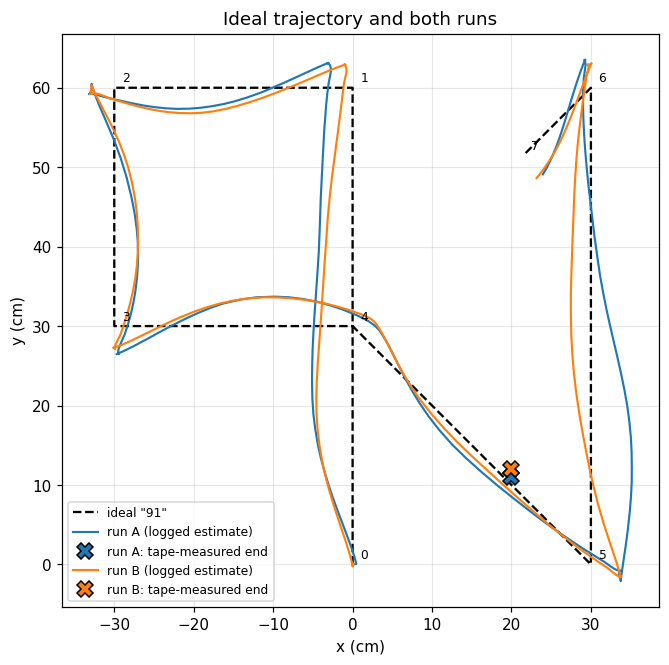

In [4]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(X_ref, Y_ref, 'k--', lw=1.5, label='ideal "91"')
for k, (xr, yr) in enumerate(zip(X_ref, Y_ref)):
    ax.annotate(str(k), (xr, yr), textcoords='offset points', xytext=(5, 4), fontsize=8, color='k')
col = {'A': 'tab:blue', 'B': 'tab:orange'}
for run, (df, m) in D.items():
    ax.plot(df.x, df.y, color=col[run], lw=1.4, label=f'run {run} (logged estimate)')
    if END_MEAS.get(run):
        ax.plot(*END_MEAS[run][:2], 'X', color=col[run], ms=11, mec='k', label=f'run {run}: tape-measured end')
if SIM:
    for run, tr in TR.items():
        ax.plot(tr.x, tr.y, ':', color=col[run], lw=2, label=f'run {run}: 2D-model truth')
ax.set_aspect('equal'); ax.set_xlabel('x (cm)'); ax.set_ylabel('y (cm)'); ax.legend(fontsize=8, loc='lower left')
ax.set_title('Ideal trajectory and both runs'); plt.show()

## Step 4.2 — Offline recomputation: 4 paths

Each run is steered by its own course, so its own estimate always looks like the digits. The **other** method,
recomputed from the same log, shows where the two sensors disagree about what really happened.

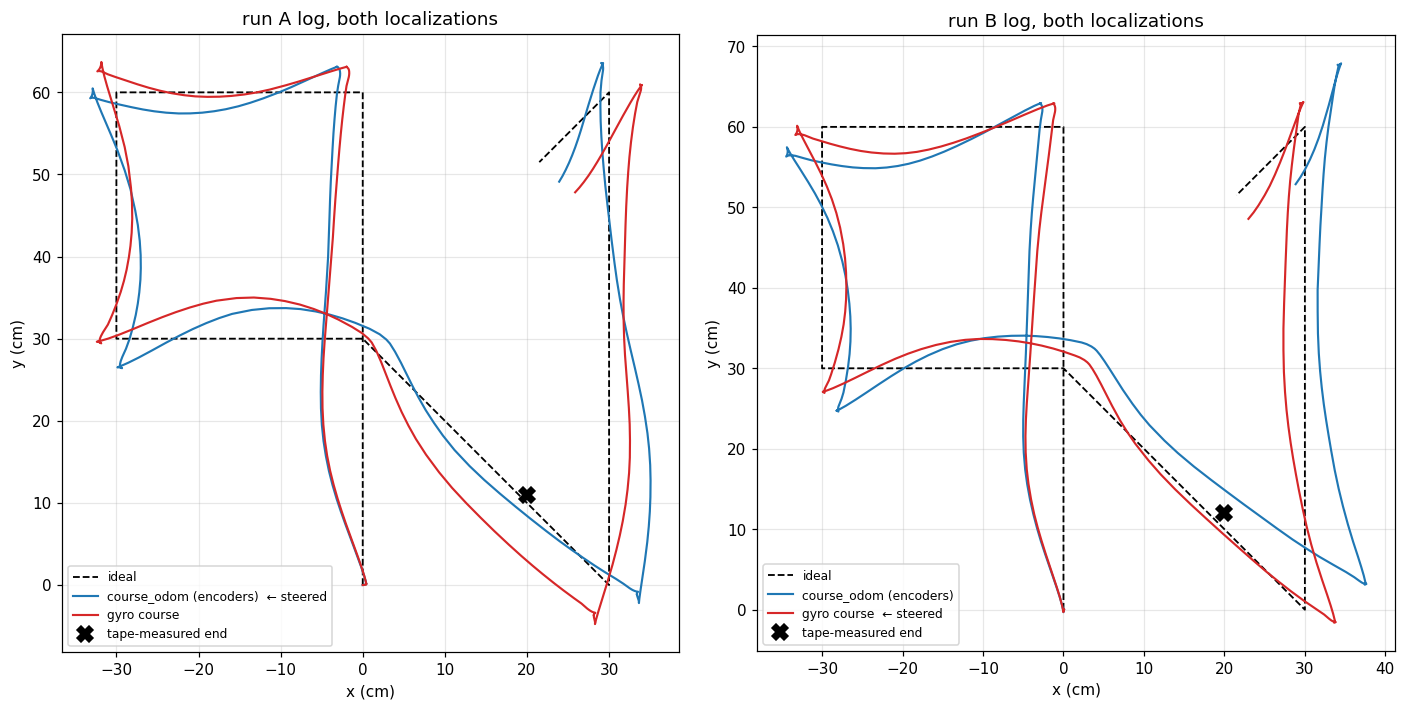

run A: end odom (23.9, 49.1)  end gyro (25.9, 47.8) cm, gap 2.3 cm, course gyro − odom at the end -11.2 deg
run B: end odom (28.9, 52.9)  end gyro (23.0, 48.6) cm, gap 7.3 cm, course gyro − odom at the end -3.8 deg


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 6.3))
for ax, run in zip(axs, 'AB'):
    ax.plot(X_ref, Y_ref, 'k--', lw=1.2, label='ideal')
    for use, ls in (('odom', '-'), ('gyro', '-')):
        r = REC[run, use]
        ax.plot(r.x, r.y, ls, lw=1.4, color='tab:blue' if use == 'odom' else 'tab:red',
                label=f'{"course_odom (encoders)" if use == "odom" else "gyro course"}' + ('  ← steered' if OWN[run] == use else ''))
    if END_MEAS.get(run):
        ax.plot(*END_MEAS[run][:2], 'kX', ms=11, label='tape-measured end')
    ax.set_aspect('equal'); ax.set_title(f'run {run} log, both localizations'); ax.legend(fontsize=8, loc='lower left')
    ax.set_xlabel('x (cm)'); ax.set_ylabel('y (cm)')
plt.tight_layout(); plt.show()
for run in 'AB':
    o, g = REC[run, 'odom'], REC[run, 'gyro']
    print(f'run {run}: end odom ({o.x.iloc[-1]:.1f}, {o.y.iloc[-1]:.1f})  end gyro ({g.x.iloc[-1]:.1f}, {g.y.iloc[-1]:.1f}) cm,'
          f' gap {np.hypot(o.x.iloc[-1] - g.x.iloc[-1], o.y.iloc[-1] - g.y.iloc[-1]):.1f} cm,'
          f' course gyro − odom at the end {np.degrees(g.course.iloc[-1] - o.course.iloc[-1]):+.1f} deg')

### Where do the two methods disagree?

`course_gyro − course_odom` over time. A **step at a turn** = wheel slip or a wrong `r/B` (encoders), or scale factor (gyro);
a **slope while driving straight or standing** = gyro bias left after calibration.

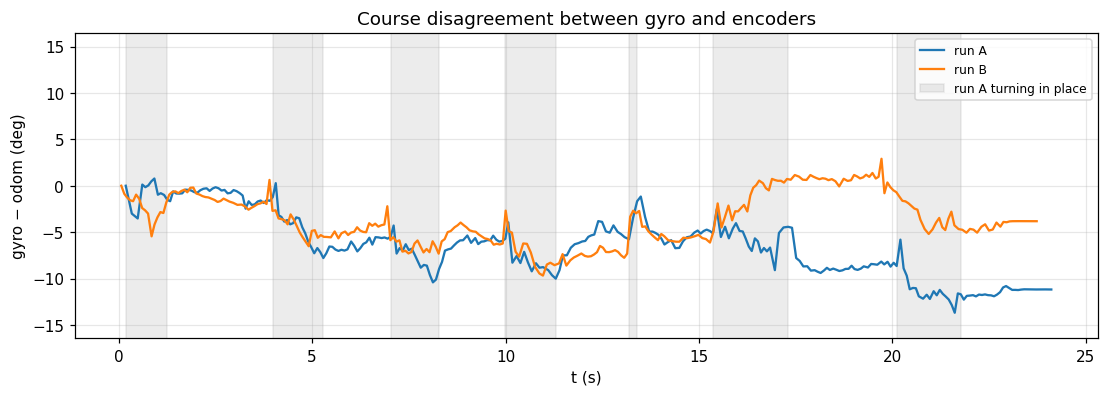

run A
 seg  turn: Δ(gyro−odom) deg  straight: Δ(gyro−odom) deg  turn size (odom) deg
   1                   -1.67                        0.04                 94.39
   2                   -5.65                        1.57                105.43
   3                   -2.51                        2.26                107.38
   4                   -3.15                        3.56                114.53
   5                    4.38                       -3.72                -28.58
   6                    0.35                       -3.77                123.40
   7                   -3.97                        1.46                145.48
run B
 seg  turn: Δ(gyro−odom) deg  straight: Δ(gyro−odom) deg  turn size (odom) deg
   1                   -2.94                        1.22                 92.44
   2                   -3.89                        1.35                105.00
   3                   -3.07                        0.99                117.56
   4                   -2.03            

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.6))
span = 1.0
for run, (df, m) in D.items():
    r = REC[run, 'odom']
    d = np.degrees(r.course_gyro - r.course_odom); span = max(span, np.abs(d).max())
    ax.plot(df.t_s, d, color=col[run], label=f'run {run}')
dfa = D['A'][0]
turn = ((dfa.pL + dfa.pR).abs() < 1e-6) & (dfa.pR.abs() > 0)
ax.fill_between(dfa.t_s, -2 * span, 2 * span, where=turn, color='grey', alpha=.15, label='run A turning in place')
ax.set_ylim(-1.2 * span, 1.2 * span); ax.set_xlabel('t (s)'); ax.set_ylabel('gyro − odom (deg)'); ax.legend(fontsize=8)
ax.set_title('Course disagreement between gyro and encoders'); plt.show()

def per_turn(df, r):
    # change of (gyro − odom) across each in-place turn and across each straight
    rows = []
    for k in range(1, NSEG + 1):
        m = (df.i == k).values
        if not m.any(): continue
        d = r.course_gyro.values - r.course_odom.values
        idx = np.flatnonzero(m)
        drv = m & (((df.pL + df.pR) / 2).values > 1)
        j = np.flatnonzero(drv)[0] if drv.any() else idx[-1]
        rows.append([k, np.degrees(d[j] - d[max(idx[0] - 1, 0)]), np.degrees(d[idx[-1]] - d[j]),
                     np.degrees(r.course_odom.values[j] - r.course_odom.values[max(idx[0] - 1, 0)])])
    return pd.DataFrame(rows, columns=['seg', 'turn: Δ(gyro−odom) deg', 'straight: Δ(gyro−odom) deg', 'turn size (odom) deg'])
for run in 'AB':
    print(f'run {run}'); print(per_turn(D[run][0], REC[run, 'odom']).round(2).to_string(index=False))

## Which `r` and `B`? (geometry check with the gyro)

The program used `r = 4.2 cm, B = 19.4 cm` (Lab 9: with `r = 4.2` the encoder heading matched the gyro). After the runs
the robot was measured with a ruler: wheel diameter **7.5 cm** (`r = 3.75`), distance between the wheels **19.6 cm**.

`course_odom` only depends on the ratio `r/B`; `path` only on `r`. The gyro measures the real rotation, so a line fit of
gyro course against the wheel-angle difference `θ_r − θ_l` gives the **real** `r/B` of this robot on this floor.

run  r/B from the gyro  r/B program (4.2/19.4)  r/B ruler (3.75/19.6)  B_eff for r = 3.75 (cm)
  A             0.2128                  0.2165                 0.1913                  17.6230
  B             0.2166                  0.2165                 0.1913                  17.3117
program r/B is off by +0.8 %, the ruler r/B by -10.9 %
path: the program counts every cm as 4.2/3.75 = 1.120 -> the real path is -10.7 % of the logged one


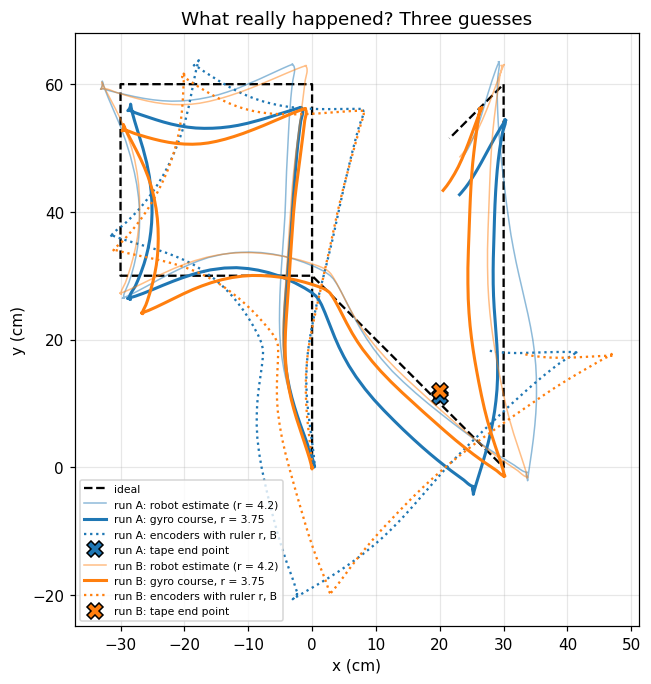

run A: path with r = 3.75: 257.9 cm (ideal 264.4, -2.5 %), end (23.1, 42.7) cm
run B: path with r = 3.75: 260.2 cm (ideal 264.4, -1.6 %), end (20.5, 43.4) cm


In [7]:
rows = []
for run, (df, m) in D.items():
    wd = np.radians(df.encR.values - df.encL.values)
    k = np.polyfit(wd, REC[run, 'odom'].course_gyro.values, 1)[0]
    rows.append([run, k, m['r'] / m['B'], R_MEAS / B_MEAS, R_MEAS / k])
GEO = pd.DataFrame(rows, columns=['run', 'r/B from the gyro', 'r/B program (4.2/19.4)', 'r/B ruler (3.75/19.6)', 'B_eff for r = 3.75 (cm)'])
print(GEO.round(4).to_string(index=False))
k_mean = GEO['r/B from the gyro'].mean()
print(f'program r/B is off by {100 * (D["A"][1]["r"] / D["A"][1]["B"] / k_mean - 1):+.1f} %, the ruler r/B by {100 * (R_MEAS / B_MEAS / k_mean - 1):+.1f} %')
print(f'path: the program counts every cm as 4.2/3.75 = {4.2 / R_MEAS:.3f} -> the real path is {100 * (R_MEAS / 4.2 - 1):+.1f} % of the logged one')

# best guess of the real path: gyro course (real rotation) + path with the ruler radius
BEST = {run: localize(df, dict(m, r=R_MEAS), 'gyro') for run, (df, m) in D.items()}
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(X_ref, Y_ref, 'k--', lw=1.5, label='ideal')
for run in 'AB':
    df = D[run][0]
    ax.plot(df.x, df.y, color=col[run], lw=1, alpha=.5, label=f'run {run}: robot estimate (r = 4.2)')
    ax.plot(BEST[run].x, BEST[run].y, color=col[run], lw=2, label=f'run {run}: gyro course, r = 3.75')
    alt = localize(df, dict(D[run][1], r=R_MEAS, B=B_MEAS), 'odom')
    ax.plot(alt.x, alt.y, ':', color=col[run], lw=1.5, label=f'run {run}: encoders with ruler r, B')
    if END_MEAS.get(run):
        ax.plot(*END_MEAS[run][:2], 'X', color=col[run], ms=11, mec='k', label=f'run {run}: tape end point')
ax.set_aspect('equal'); ax.legend(fontsize=7, loc='lower left'); ax.set_xlabel('x (cm)'); ax.set_ylabel('y (cm)')
ax.set_title('What really happened? Three guesses'); plt.show()
for run in 'AB':
    b = BEST[run]
    print(f'run {run}: path with r = 3.75: {b.path.iloc[-1]:.1f} cm (ideal {path_ref.sum():.1f}, {100 * (b.path.iloc[-1] / path_ref.sum() - 1):+.1f} %),'
          f' end ({b.x.iloc[-1]:.1f}, {b.y.iloc[-1]:.1f}) cm')

## Steps 4.3–4.4 — Course and path per segment

A segment `k` = log lines with target waypoint `i = k`. Its **course** = mean course while driving (`(pL + pR)/2 > 1`, the
in-place turn excluded); its **path** = increase of `path = (θ_r + θ_l)·r/2` from reaching waypoint `k − 1` to reaching `k`.

In [8]:
def seg_table(df, r):
    rows = []
    for k in range(1, NSEG + 1):
        m = (df.i == k).values
        drv = m & (((df.pL + df.pR) / 2).values > 1)
        c = r.course.values[drv].mean() if drv.any() else np.nan
        p_end = r.path.values[(df.i <= k).values][-1]
        p_start = r.path.values[(df.i <= k - 1).values][-1] if k > 1 else 0.0
        rows.append([k, c, p_end - p_start])
    t = pd.DataFrame(rows, columns=['seg', 'course', 'path'])
    t['d_course'] = wrap(t.course - course_ref); t['d_path'] = t.path - path_ref
    return t

SEG = {(run, use): seg_table(D[run][0], REC[run, use]) for run in 'AB' for use in ('odom', 'gyro')}
A, B = SEG['A', 'odom'], SEG['B', 'gyro']          # each run with the course it steered with
T = pd.DataFrame({
    'Seg.': A.seg, 'course_ref (°)': np.degrees(course_ref), 'course A (°)': np.degrees(A.course),
    'course B (°)': np.degrees(B.course), 'd_course A (°)': np.degrees(A.d_course), 'd_course B (°)': np.degrees(B.d_course),
    'path_ref (cm)': path_ref, 'path A (cm)': A.path, 'path B (cm)': B.path, 'd_path A (cm)': A.d_path, 'd_path B (cm)': B.d_path})
summ = {'Seg.': 'Summary', 'd_course A (°)': np.degrees(A.d_course.abs().mean()), 'd_course B (°)': np.degrees(B.d_course.abs().mean()),
        'path_ref (cm)': path_ref.sum(), 'path A (cm)': A.path.sum(), 'path B (cm)': B.path.sum(),
        'd_path A (cm)': A.d_path.sum(), 'd_path B (cm)': B.d_path.sum()}
T = pd.concat([T, pd.DataFrame([summ])], ignore_index=True)
pd.set_option('display.width', 200)
print(T.round(2).fillna('').to_string(index=False))
print(f"summary row: d_course = mean |d_course|; d_path = total; "
      f"total path error A {100 * A.d_path.sum() / path_ref.sum():+.2f} %, B {100 * B.d_path.sum() / path_ref.sum():+.2f} %")

   Seg. course_ref (°) course A (°) course B (°)  d_course A (°)  d_course B (°)  path_ref (cm)  path A (cm)  path B (cm)  d_path A (cm)  d_path B (cm)
      1           90.0        95.28        93.12            5.28            3.12          60.00        59.49        58.97          -0.51          -1.03
      2          180.0       190.36       188.71           10.36            8.71          30.00        32.51        33.79           2.51           3.79
      3          270.0       278.91       279.96            8.91            9.96          30.00        32.69        34.09           2.69           4.09
      4          360.0       371.14       369.04           11.14            9.04          30.00        35.44        35.19           5.44           5.19
      5          315.0       312.22       310.66           -2.78           -4.34          42.43        43.80        43.65           1.37           1.23
      6          450.0       453.62       455.27            3.62            5.27        

**Cross-check with the other sensor.** The table above uses the course each run steered with, which the controller drives to
`course_ref` — so it mostly shows how well the controller tracked. The same table with the **other** sensor's course shows
the real heading error (if that sensor is the better one):

In [9]:
X = pd.DataFrame({'Seg.': range(1, NSEG + 1),
                  'run A: gyro d_course (°)': np.degrees(SEG['A', 'gyro'].d_course),
                  'run B: odom d_course (°)': np.degrees(SEG['B', 'odom'].d_course)})
print(X.round(2).to_string(index=False))
print(f"mean |d_course|: run A seen by gyro {np.degrees(SEG['A', 'gyro'].d_course.abs().mean()):.2f}°, "
      f"run B seen by encoders {np.degrees(SEG['B', 'odom'].d_course.abs().mean()):.2f}°")

 Seg.  run A: gyro d_course (°)  run B: odom d_course (°)
    1                      4.34                      4.55
    2                      3.99                     13.66
    3                      2.73                     15.30
    4                      5.40                     16.47
    5                     -7.96                      1.03
    6                     -5.02                      4.50
    7                     12.87                     25.64
mean |d_course|: run A seen by gyro 6.04°, run B seen by encoders 11.59°


### Course over time

`course(t)` and `course_odom(t)` of both runs over the `course_ref` staircase (`course_ref` of the current target segment).

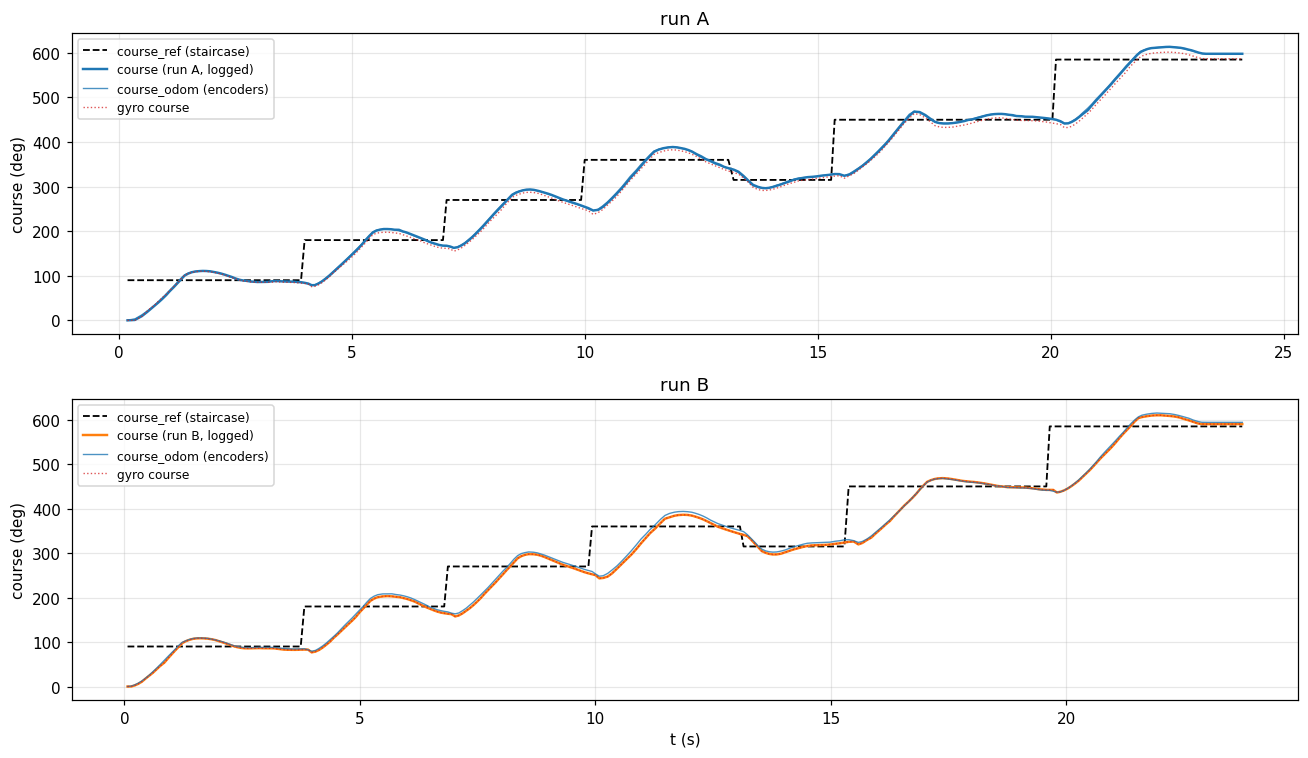

In [10]:
fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
for ax, run in zip(axs, 'AB'):
    df, m = D[run]; r = REC[run, 'odom']
    stair = np.degrees(course_ref[np.clip(df.i.values, 1, NSEG) - 1])
    ax.plot(df.t_s, stair, 'k--', lw=1.2, label='course_ref (staircase)')
    ax.plot(df.t_s, np.degrees(df.course), color=col[run], lw=1.6, label=f'course (run {run}, logged)')
    ax.plot(df.t_s, np.degrees(r.course_odom), color='tab:blue', lw=.9, alpha=.8, label='course_odom (encoders)')
    ax.plot(df.t_s, np.degrees(r.course_gyro), color='tab:red', lw=.9, alpha=.8, ls=':', label='gyro course')
    ax.set_ylabel('course (deg)'); ax.set_title(f'run {run}'); ax.legend(fontsize=8, loc='upper left')
axs[-1].set_xlabel('t (s)'); plt.tight_layout(); plt.show()

## Step 4.5 — Error growth

Distance from the position to the ideal trajectory (shortest distance to the polyline), its maximum on each segment, for the
4 recomputed paths, and `d_course` per segment. Does it accumulate or stay bounded? After which turn does it jump?

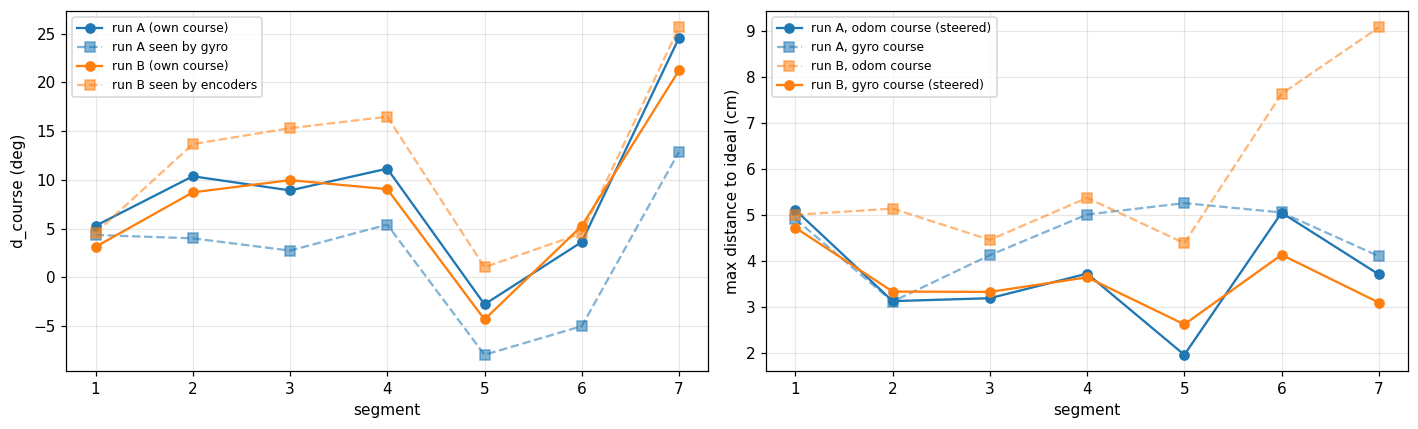

In [11]:
def dist_to_polyline(x, y):
    best = np.full(len(x), np.inf)
    for k in range(NSEG):
        ax_, ay_, bx, by = X_ref[k], Y_ref[k], X_ref[k + 1], Y_ref[k + 1]
        vx, vy = bx - ax_, by - ay_
        u = np.clip(((x - ax_) * vx + (y - ay_) * vy) / (vx * vx + vy * vy), 0, 1)
        best = np.minimum(best, np.hypot(x - ax_ - u * vx, y - ay_ - u * vy))
    return best

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
G = {}
for run in 'AB':
    df = D[run][0]
    for use in ('odom', 'gyro'):
        r = REC[run, use]; dd = dist_to_polyline(r.x.values, r.y.values)
        G[run, use] = [dd[(df.i == k).values].max() if (df.i == k).any() else np.nan for k in range(1, NSEG + 1)]
        axs[1].plot(range(1, NSEG + 1), G[run, use], 'o-' if use == OWN[run] else 's--', color=col[run],
                    alpha=1 if use == OWN[run] else .55, label=f'run {run}, {use} course' + (' (steered)' if use == OWN[run] else ''))
    axs[0].plot(range(1, NSEG + 1), np.degrees(SEG[run, OWN[run]].d_course), 'o-', color=col[run], label=f'run {run} (own course)')
    axs[0].plot(range(1, NSEG + 1), np.degrees(SEG[run, 'gyro' if run == 'A' else 'odom'].d_course), 's--', color=col[run],
                alpha=.55, label=f'run {run} seen by {"gyro" if run == "A" else "encoders"}')
axs[0].set_ylabel('d_course (deg)'); axs[1].set_ylabel('max distance to ideal (cm)')
for a in axs: a.set_xlabel('segment'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Final errors (deliverable 4)

Relative to the last waypoint (21.5, 51.5) cm and the last `course_ref`. The logged estimate always ends within the
acceptance radius — the real error needs the tape (`END_MEAS`) or the other sensor.

In [12]:
rows = []
for run in 'AB':
    df = D[run][0]
    for name, (x, y, c) in {'logged estimate': (df.x.iloc[-1], df.y.iloc[-1], df.course.iloc[-1]),
                            'recomputed, encoder course': tuple(REC[run, 'odom'][['x', 'y', 'course']].iloc[-1]),
                            'recomputed, gyro course': tuple(REC[run, 'gyro'][['x', 'y', 'course']].iloc[-1])}.items():
        rows.append([run, name, np.hypot(x - X_ref[-1], y - Y_ref[-1]), np.degrees(wrap(c - course_ref[-1]))])
    if END_MEAS.get(run):
        xm, ym, hm = END_MEAS[run]
        rows.append([run, 'tape measurement', np.hypot(xm - X_ref[-1], ym - Y_ref[-1]),
                     np.nan if hm is None else np.degrees(wrap(np.radians(hm) - course_ref[-1]))])
    rows.append([run, 'best guess: gyro course, r = 3.75', np.hypot(BEST[run].x.iloc[-1] - X_ref[-1], BEST[run].y.iloc[-1] - Y_ref[-1]),
                 np.degrees(wrap(BEST[run].course.iloc[-1] - course_ref[-1]))])
    if SIM:
        tr = TR[run]
        rows.append([run, '2D-model truth', np.hypot(tr.x.iloc[-1] - X_ref[-1], tr.y.iloc[-1] - Y_ref[-1]),
                     np.degrees(wrap(tr.course.iloc[-1] - course_ref[-1]))])
FE = pd.DataFrame(rows, columns=['run', 'source', 'final position error (cm)', 'final course error (deg)'])
print(FE.round(2).to_string(index=False))

run                            source  final position error (cm)  final course error (deg)
  A                   logged estimate                       3.43                     12.96
  A        recomputed, encoder course                       3.39                     12.96
  A           recomputed, gyro course                       5.71                      1.77
  A                  tape measurement                      40.53                       NaN
  A best guess: gyro course, r = 3.75                       8.94                      1.77
  B                   logged estimate                       3.32                      5.24
  B        recomputed, encoder course                       7.48                      9.06
  B           recomputed, gyro course                       3.29                      5.24
  B                  tape measurement                      39.53                       NaN
  B best guess: gyro course, r = 3.75                       8.19                      5.24

## Short analysis

Real runs 2026-11-26, robot 192.168.50.198 (battery 12.5 V), loop period 78 ms (diagram compiled to JS). The robot was
measured after the runs: wheel diameter 7.5 cm, 19.6 cm between the wheels. The programs used `r = 4.2`, `B = 19.4` (Lab 9).

**Course or path: which run is closer?** Each run steered by its own course, so both estimates follow the digits about
equally well (mean |`d_course`| 9.5° / 8.8°). Most of that comes from the controller, not from the sensors: every in-place
turn overshoots by 5–25°, because one 78-ms step at 100 °/s is 8°. The heading hold then corrects it on the straight. The gyro
shows the real heading, and it decides the run. In run A the encoder course drifted away from the real one by **−11°** by the end.
Almost every left turn added −2 to −6° (turn 6 is the exception), while the encoders counted more rotation than the robot made. In run B the gyro course had no
such drift: the calibration check left only −0.16 °/min, i.e. 0.06° in a 24-s run. So **run B is closer in course**.
**Path is the same** in both runs (+8.2 % / +8.8 % against the ideal 264 cm, from weaving and corner overshoot). Both runs take
`path` from the same encoders with the same `r`. The course is the only thing that changed between A and B.

**Which error source?** The offline recomputation answers it. Seen by the gyro, run A's real course error grows in steps
at the turns (gap −1.6 → −5.7 → −6.0 → … → −10.8° at the segment ends). That is **wheel slip/scrub in the in-place turns**:
a step at almost every turn, the same sign, while the straights add only ±1–4°. Bias is ruled out: < 0.1° per run after the
on-robot calibration. Scale factor is ruled out too: Lab 9 found `s` = +0.16 %, which is 1° over 585°. For `B`, the gyro fit gives
the real `r/B` = 0.213–0.217, and the program's 4.2/19.4 = 0.2165 is within +0.8 %. The ruler values 3.75/19.6 would be
**−10.9 %**: with them, run A's encoder course would end 58° short. The wheels touch the floor inside their 19.6-cm spacing, so the
effective track is ≈ 17.5 cm for `r = 3.75`. The `r = 4.2` from Lab 9 was really a correction of `r/B`, not of `r`. Because of
it, `path` is **12 % too long** (4.2/3.75), so the real digits are about 11 % smaller than the estimate. With `r = 3.75` and
the gyro course, the real path is 258 / 260 cm (−2.5 / −1.6 %), and the end point is 8.9 / 8.2 cm from the last waypoint.

**Tape check.** The end points were measured as (20, 11) and (20, 12) cm. x agrees with the best guess (23 / 20.5 cm), but y is
≈ 32 cm lower than every reconstruction, in both runs by the same amount. That points to a different reference for y
(not the start cross), so the tape y is not used for conclusions.

**How to combine them (→ Lab 11).** The encoders are wrong in short, sharp events (slip in a turn, a bump). The gyro is wrong
slowly (bias drift, < 0.2 °/min here). So take the course **changes** from the gyro and let the encoder course pull the
estimate back only slowly: `course = K·(course + gyro_inc) + (1 − K)·course_odom`, with `K` close to 1. With the 78-ms loop
and K = 0.98, τ = K·dt/(1−K) ≈ 3.8 s.